# 05b · Torneo de modelos — elegir finalistas con evidencia

> Continúa `01b_caso_negocio_aprueba_o_no.ipynb` (**aprueba con 70 o más; con menos de 70 pierde el curso**; clase de interés `Fail`, 69,2 %; costos 5 : 1; métricas: costo por estudiante, *recall* de `Fail` y NPV),
> `03b_preprocesamiento_aprueba_o_no.ipynb` (deja `data/processed/train.joblib`) y `04b_features_aprueba_o_no.ipynb` (propuesta: **28 variables**, sin indicador de vacío, sin variables nuevas).
> Dataset: `data/student_exam_performance.csv`. Plantilla: `notebooks/05_torneo.ipynb`. Ejemplo de referencia: `material-del-curso/ejemplo-creditsight/notebooks/05_torneo.ipynb`.

Objetivo: elegir **uno o dos finalistas** para optimizar, con evidencia y **sin abrir la prueba**. Un torneo bien hecho tiene tres reglas:

1. **Mismos datos y misma validación para todos** (los mismos 5 pliegues de la etapa 4: por fila, estratificados por `pass_70`, semilla 42).
2. **Un punto de referencia** que cualquier modelo serio debe vencer. Aquí es **«avisar a todos»** (costo 0,308 por estudiante); un modelo la supera solo con NPV > 83,3 %.
3. **Mirar la variabilidad**, no solo el promedio: una diferencia menor que lo que varía entre pliegues no es una victoria.

| Candidato | Por qué está |
|---|---|
| Línea base (avisar a todos) | Piso: lo que se logra sin aprender nada. `DummyClassifier` que siempre predice la tasa de `Fail` (69,2 %); con el umbral de 0,167 equivale a avisar a todos |
| Regresión logística | Simple e interpretable: cada variable tiene un peso que se puede explicar a un coordinador académico |
| Random forest | Ensamble de árboles independientes: robusto, pocos supuestos |
| LightGBM | Boosting rápido y muy competitivo en datos tabulares |
| XGBoost | Boosting de referencia; vale compararlo con LightGBM |

Todos usan la **misma configuración de variables** decidida en la etapa 4 (`STAGE4_DROP`: 28 variables, con `exam_difficulty`, que **está por confirmar** que se conozca al avisar; ver la sección 7).

**Diferencias con el ejemplo CreditSight.** Allí el objetivo tenía 3 clases (`Poor`, `Standard`, `Good`), se partía por cliente y la decisión salía de una matriz de costos 3 × 3. Aquí el objetivo tiene **2 clases**, los pliegues son **por fila** (`student_id` único) y la decisión es una sola: **avisar si P(`Fail`) ≥ 1 / (1 + 5) = 0,167**. El equivalente del *recall* de `Good` (la clase que casi nunca se acierta) es la **especificidad**: de los que aprobarían, cuántos se dejan tranquilos.

**Reglas de decisión (escritas ANTES de correr el torneo):**
- Un modelo que **no supera** a «avisar a todos» (costo mayor o igual a 0,308) queda fuera.
- Dos modelos **empatados** (diferencia / ruido menor que 1 y sin ganar en todos los pliegues) se desempatan por **simplicidad e interpretabilidad**, después por tiempo de ajuste.
- Máximo **2 finalistas**. El torneo **descarta**; no corona.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

import joblib
import matplotlib.pyplot as plt

from proyecto.data.cleaning import LEAK_COLUMNS, TARGET
from proyecto.data.split import make_folds
from proyecto.features.engineering import STAGE4_ADD_MISSING_INDICATOR, STAGE4_DROP, TIMING_COLUMNS, feature_columns
from proyecto.models.train import (FALSE_NEGATIVE_COST, FALSE_POSITIVE_COST, TOP_K_PERCENTS, build_pipeline,
                                   candidates, encode_target, evaluate_folds)

ROOT = Path.cwd().resolve().parent
SEED = 42

## 0. Cargar los datos de entrenamiento y los pliegues

In [2]:
train_path = ROOT / "data" / "processed" / "train.joblib"
assert train_path.exists(), "Falta data/processed/train.joblib: ejecuta antes el notebook 03b_preprocesamiento_aprueba_o_no."
train = joblib.load(train_path)                      # SOLO entrenamiento: test.joblib NO se abre en esta etapa
X, y = train.drop(columns=[TARGET]), encode_target(train[TARGET])      # y: 1 = Fail (clase de interés), 0 = Pass
pliegues = make_folds(train[TARGET], n_splits=5, seed=SEED)            # los MISMOS de la etapa 4

numeric_final, categorical_final = feature_columns(drop=STAGE4_DROP)
FORBIDDEN = {"exam_score", "pass_status", "performance_grade", "performance_level", "questions_correct",
             "questions_attempted", "student_id", "gender", "family_income", TARGET}
checks = {
    "80.000 estudiantes de entrenamiento": len(train) == 80_000,
    "student_id no se repite (partir por fila es válido)": train.index.is_unique,
    "cada estudiante se valida exactamente una vez": sorted(np.concatenate([v for _, v in pliegues])) == list(range(len(train))),
    "la configuración de la etapa 4 tiene 28 variables": len(numeric_final) + len(categorical_final) == 28,
    "ninguna columna de fuga ni sensible entre las variables finales": not (FORBIDDEN | set(LEAK_COLUMNS)) & set(numeric_final + categorical_final),
}
result = pd.Series(checks, name="se cumple")
assert result.all(), result[~result]
display(result)
print(f"{len(X):,} estudiantes de entrenamiento · {len(pliegues)} pliegues por fila · Fail = {y.mean():.1%} · la prueba sigue cerrada")

80.000 estudiantes de entrenamiento                                True
student_id no se repite (partir por fila es válido)                True
cada estudiante se valida exactamente una vez                      True
la configuración de la etapa 4 tiene 28 variables                  True
ninguna columna de fuga ni sensible entre las variables finales    True
Name: se cumple, dtype: bool

80,000 estudiantes de entrenamiento · 5 pliegues por fila · Fail = 69.2% · la prueba sigue cerrada


## 1. Correr el torneo

Cada candidato se entrena y se valida en los 5 pliegues, con el **mismo `Pipeline`** (imputación y codificación dentro, ajustadas solo con el entrenamiento de cada pliegue). Se guarda **cada pliegue** (no solo el promedio) para poder comparar de a pares. La regresión logística recibe variables escaladas; los árboles no lo necesitan.

In [3]:
OPCIONES = dict(drop=STAGE4_DROP, add_missing_indicator=STAGE4_ADD_MISSING_INDICATOR)     # propuesta de la etapa 4

resultados = {}
for name, (model, scale) in candidates(SEED).items():
    resultados[name] = evaluate_folds(build_pipeline(model, scale=scale, **OPCIONES), X, y, pliegues)
    f = resultados[name]
    print(f"{name:30s} costo = {f['cost'].mean():.4f} ± {f['cost'].std():.4f}   ({f['fit_seconds'].mean():.1f} s por ajuste)")

línea base (avisar a todos)    costo = 0.3079 ± 0.0000   (0.2 s por ajuste)


regresión logística            costo = 0.2576 ± 0.0032   (0.7 s por ajuste)


random forest                  costo = 0.2827 ± 0.0010   (4.7 s por ajuste)


lightgbm                       costo = 0.2584 ± 0.0030   (0.9 s por ajuste)


xgboost                        costo = 0.2583 ± 0.0034   (1.4 s por ajuste)


## 2. Tabla resumen y variabilidad

*Costo* = costo esperado por estudiante con la **regla de negocio** (avisar si P(`Fail`) ≥ 0,167). *Costo con la clase más probable* = el mismo costo si se avisara solo cuando P(`Fail`) ≥ 0,5, sin mirar los costos. *NPV* = de los estudiantes que se dejan tranquilos, cuántos aprueban de verdad (hace falta **> 83,3 %** para superar a «avisar a todos»). La línea base no tranquiliza a nadie, por eso su NPV no existe (vacío).

In [4]:
def media(col):
    return {n: f[col].mean() for n, f in resultados.items()}


BASELINE = next(iter(resultados))
resumen = pd.DataFrame({
    "costo": media("cost"),
    "± pliegues": {n: f["cost"].std() for n, f in resultados.items()},
    "costo (clase más probable)": media("cost_argmax"),
    "log loss": media("log_loss"),
    "recall Fail": media("recall_fail"),
    "NPV": media("npv"),
    "alertas por 100": media("alerts_per_100"),
    "segundos por ajuste": media("fit_seconds"),
}).sort_values("costo")
(ROOT / "reports").mkdir(exist_ok=True)
resumen.round(5).to_csv(ROOT / "reports" / "05_torneo_tabla.csv")
display(resumen.round(4))

NPV_MIN = FALSE_NEGATIVE_COST / (FALSE_NEGATIVE_COST + FALSE_POSITIVE_COST)
supera = {n: bool(resumen.loc[n, "costo"] < resumen.loc[BASELINE, "costo"]) for n in resumen.index if n != BASELINE}
print(f"Línea base («avisar a todos»): costo {resumen.loc[BASELINE, 'costo']:.4f}. ¿La supera cada modelo? {supera}")

,costo,± pliegues,costo (clase más probable),log loss,recall Fail,NPV,alertas por 100,segundos por ajuste
regresión logística,0.2576,0.0032,0.4371,0.3728,0.9879,0.9170,89.9562,0.7471
xgboost,0.2583,0.0034,0.4474,0.3702,0.9880,0.9166,90.0425,1.3534
lightgbm,0.2584,0.0030,0.4474,0.3702,0.9881,0.9169,90.1000,0.8897
random forest,0.2827,0.0010,0.3922,0.3997,0.9990,0.9767,97.0638,4.7385
línea base (avisar a todos),0.3079,0.0000,0.3079,0.6174,1.0000,NaN,100.0000,0.1820


Línea base («avisar a todos»): costo 0.3079. ¿La supera cada modelo? {'regresión logística': True, 'xgboost': True, 'lightgbm': True, 'random forest': True}


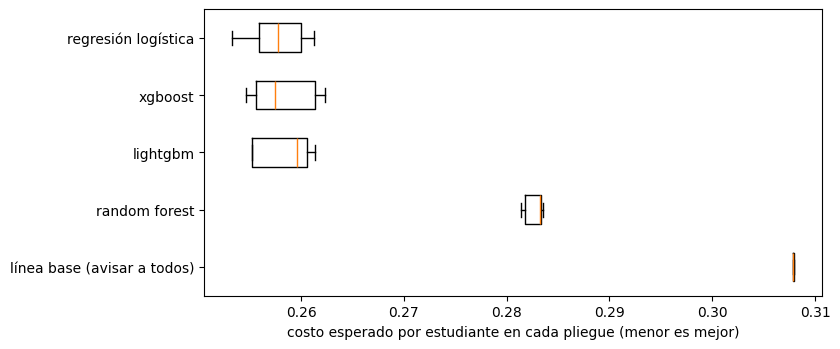

In [5]:
orden = resumen.index.tolist()
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.boxplot([resultados[n]["cost"] for n in orden], vert=False, tick_labels=orden, widths=0.5)
ax.invert_yaxis(); ax.set_xlabel("costo esperado por estudiante en cada pliegue (menor es mejor)")
plt.tight_layout(); plt.show()

## 3. Las métricas técnicas (no solo el costo)

El costo dice qué conviene al **negocio**, pero un modelo también se juzga con las métricas **técnicas** de siempre, en los mismos pliegues. Las de *ranking* (ROC-AUC, PR-AUC) miran las probabilidades y **no dependen de ninguna decisión**; las de clasificación usan la decisión de negocio (umbral 0,167).

| Métrica | Qué mide |
|---|---|
| **ROC-AUC** | Qué tan bien **ordena** a los estudiantes: 0,5 es azar, 1 es perfecto |
| **PR-AUC de `Fail`** | Lo mismo para la clase que importa; el azar da 0,692 (la tasa de `Fail`), no 0,5 |
| **Recall de `Fail`** | De los que **pierden** el curso, ¿qué proporción avisó el modelo? |
| **Precisión de `Fail`** | De los que el modelo **marcó**, ¿cuántos perdían de verdad? (hay que superar 69,2 %) |
| **Especificidad (recall de `Pass`)** | De los que **aprobarían**, ¿cuántos deja tranquilos? Es el equivalente del recall de `Good` en CreditSight |
| **Exactitud balanceada** | Promedio del recall de las dos clases (la exactitud simple premia avisar a todos: 69,2 %) |

In [6]:
tecnicas = pd.DataFrame({
    "ROC-AUC": media("roc_auc"),
    "PR-AUC Fail": media("pr_auc_fail"),
    "exactitud": media("accuracy"),
    "exactitud balanceada": media("balanced_accuracy"),
    "F1 Fail": media("f1_fail"),
    "precisión Fail": media("precision_fail"),
    "recall Fail": media("recall_fail"),
    "especificidad (recall Pass)": media("specificity"),
}).loc[resumen.index]
tecnicas.round(5).to_csv(ROOT / "reports" / "05_torneo_tecnicas.csv")
display(tecnicas.round(3))

,ROC-AUC,PR-AUC Fail,exactitud,exactitud balanceada,F1 Fail,precisión Fail,recall Fail,especificidad (recall Pass)
regresión logística,0.892,0.949,0.776,0.643,0.859,0.760,0.988,0.299
xgboost,0.894,0.950,0.775,0.642,0.859,0.759,0.988,0.296
lightgbm,0.894,0.950,0.775,0.641,0.859,0.759,0.988,0.295
random forest,0.885,0.944,0.720,0.546,0.832,0.712,0.999,0.093
línea base (avisar a todos),0.500,0.692,0.692,0.500,0.818,0.692,1.000,0.000


### ¿Coincide el ranking técnico con el del negocio?

Un modelo puede ser el mejor para el negocio y no serlo en una métrica técnica, y al revés. Se comparan las posiciones (1 = mejor):

In [7]:
ranking = pd.DataFrame({
    "costo (negocio)": resumen["costo"].rank(method="min"),
    "ROC-AUC": tecnicas["ROC-AUC"].rank(ascending=False, method="min"),
    "PR-AUC Fail": tecnicas["PR-AUC Fail"].rank(ascending=False, method="min"),
    "F1 Fail": tecnicas["F1 Fail"].rank(ascending=False, method="min"),
    "recall Fail": tecnicas["recall Fail"].rank(ascending=False, method="min"),
    "especificidad": tecnicas["especificidad (recall Pass)"].rank(ascending=False, method="min"),
    "log loss": resumen["log loss"].rank(method="min"),
}).astype(int)
display(ranking)
modelos = [n for n in resumen.index if n != BASELINE]
mejor_costo = resumen.loc[modelos, "costo"].idxmin()
mejor_auc = tecnicas.loc[modelos, "ROC-AUC"].idxmax()
print(f"Mejor por costo (negocio): {mejor_costo}   |   mejor por ROC-AUC (ranking): {mejor_auc}")
print("Coinciden costo y ROC-AUC." if mejor_costo == mejor_auc else "NO coinciden costo y ROC-AUC: ordenar bien y decidir bien premian modelos distintos.")

,costo (negocio),ROC-AUC,PR-AUC Fail,F1 Fail,recall Fail,especificidad,log loss
regresión logística,1,3,3,1,5,1,3
xgboost,2,2,2,2,4,2,1
lightgbm,3,1,1,3,3,3,2
random forest,4,4,4,4,2,4,4
línea base (avisar a todos),5,5,5,5,1,5,5


Mejor por costo (negocio): regresión logística   |   mejor por ROC-AUC (ranking): lightgbm
NO coinciden costo y ROC-AUC: ordenar bien y decidir bien premian modelos distintos.


**Cómo leerlo.** El **ROC-AUC** dice cuánta información útil tienen las probabilidades, sin importar dónde se ponga el umbral; el **costo** y el **recall de `Fail`** dependen además de la regla de decisión. Si dos modelos ordenan casi igual pero cuestan distinto, la diferencia viene de **cómo deciden** (qué tan bien calibradas están sus probabilidades), no de **qué tan bien ordenan**.

### Lo que muestran los números (y el costo solo no dejaba ver)

- **Todos los modelos superan a «avisar a todos»** (costo 0,308): de 0,258 (regresión logística) a 0,283 (random forest). Sus NPV (91,7 % a 97,7 %) superan el mínimo de 83,3 %.
- **Tres modelos empatan en el primer puesto:** regresión logística (0,2576), XGBoost (0,2583) y LightGBM (0,2584). La diferencia es de 0,001, menor que lo que varía entre pliegues (≈ 0,003).
- **La regresión logística iguala a los modelos de boosting incluso ordenando:** ROC-AUC 0,892 frente a 0,894; PR-AUC 0,949 frente a 0,950. Los modelos más complejos **no encuentran información extra**: es una señal de que las relaciones con `Fail` son casi lineales (hipótesis: el dataset parece sintético).
- **Random forest es el peor y no es por azar** (pierde en los 5 pliegues, ver sección 5), aunque es el que menos varía entre pliegues (± 0,001). Avisa a 97 de cada 100 estudiantes y deja tranquilo solo al 9 % de los que aprobarían. Una parte de su desventaja viene de que **el umbral de 0,167 supone probabilidades bien calibradas** y las de un bosque no lo están: con la regla de la «clase más probable» es el de menor costo entre los modelos (0,392 frente a 0,437). Esto se revisa con la calibración en la etapa 7; no cambia que ordena peor (ROC-AUC 0,885).
- **Señal de alarma, equivalente al *recall* de `Good` en CreditSight:** la **especificidad** es de apenas 0,30 en la regresión logística y en los de boosting: **7 de cada 10 estudiantes que aprobarían reciben aviso**. La exactitud (0,78) se ve bien, pero la exactitud balanceada (0,64) dice la verdad. El negocio se protege (casi nadie que pierde el curso queda sin aviso: *recall* 0,99), pero **el aviso casi no discrimina**.
- **La regla de decisión de negocio es indispensable:** con la «clase más probable» (umbral 0,5) la regresión logística cuesta **0,437, peor que no hacer nada** (0,308). Con el umbral de 0,167 baja a 0,258.
- **Costo y ROC-AUC no coinciden en el mejor** (regresión logística frente a LightGBM), pero la diferencia de ROC-AUC es de 0,002: es el mismo empate visto con otra métrica.

## 4. Efectos que la métrica principal no ve: capacidad de la institución

Con costos 5 : 1 la regla de negocio **avisa a casi todos** (≈ 90 de cada 100 estudiantes): casi nadie queda tranquilo y la especificidad es baja. Si la institución solo puede atender a una parte (**capacidad de tutoría: dato que la institución debe definir**), importa **qué tan bien ordena** el modelo a los más riesgosos. Esta tabla simula avisar solo al k % con mayor P(`Fail`) en cada pliegue. El máximo *recall* posible con k % de alertas es k / 69,2 (si todas las alertas acertaran).

In [8]:
filas = []
tasa_fail = float(y.mean())
for name, f in resultados.items():
    for k in TOP_K_PERCENTS:
        filas.append({"modelo": name, "avisar al k %": k, "precisión Fail": f[f"precision_top{k}"].mean(),
                      "recall Fail": f[f"recall_top{k}"].mean(), "máximo recall posible": min(1.0, k / 100 / tasa_fail),
                      "costo por estudiante": f[f"cost_top{k}"].mean()})
capacidad = pd.DataFrame(filas).set_index(["avisar al k %", "modelo"]).sort_index()
capacidad.round(5).to_csv(ROOT / "reports" / "05_torneo_capacidad.csv")
display(capacidad.round(3))
print(f"Referencia: «avisar a todos» cuesta {resumen.loc[BASELINE, 'costo']:.3f}. Con capacidad limitada hay estudiantes en riesgo sin avisar (falsos negativos, 5 veces más caros), "
      f"por eso el costo sube aunque la precisión sea altísima.")

precisión Fail  recall Fail  máximo recall posible  costo por estudiante
avisar al k % modelo                                                                                               
30            lightgbm                              0.982        0.426                  0.433                 1.992
              línea base (avisar a todos)           0.689        0.299                  0.433                 2.521
              random forest                         0.975        0.423                  0.433                 2.005
              regresión logística                   0.983        0.426                  0.433                 1.992
              xgboost                               0.982        0.426                  0.433                 1.992
50            lightgbm                              0.943        0.681                  0.722                 1.131
              línea base (avisar a todos)           0.691        0.499                  0.722                 1.887
              random forest                         0.936        0.676                  0.722                 1.153
              regresión logística                   0.941        0.680                  0.722                 1.136
              xgboost                               0.943        0.681                  0.722                 1.132

Referencia: «avisar a todos» cuesta 0.308. Con capacidad limitada hay estudiantes en riesgo sin avisar (falsos negativos, 5 veces más caros), por eso el costo sube aunque la precisión sea altísima.


**Lo que muestra la tabla** (la «línea base» aquí equivale a avisar al azar: no ordena):

- **Los modelos ordenan casi perfecto a los más riesgosos.** Avisando solo al 30 %, la regresión logística acierta el **98,3 %** de sus alertas (el azar acierta 68,9 %) y detecta el 42,6 % de quienes pierden el curso, de un máximo posible de 43,3 %: aprovecha el **98 %** de lo que se puede lograr. Con el 50 %: precisión 94,1 % y *recall* 0,680 de un máximo de 0,722. Los cuatro modelos son casi iguales aquí (precisión 97,5–98,3 % al 30 %).
- **Pero el costo sube mucho:** 1,99 al avisar al 30 % y 1,14 al 50 %, frente a **0,308 de avisar a todos**. Con la matriz 5 : 1, cada estudiante en riesgo que no recibe aviso cuesta 5, y con cupo limitado quedan muchos sin aviso.
- **Conclusión para la institución, no técnica:** si el límite real es la **capacidad de tutoría**, el costo 5 : 1 deja de ser la métrica adecuada (siempre premia avisar a casi todos) y conviene decidir con *precisión* y *recall* al k % que se pueda atender. Si el costo 5 : 1 es el criterio, hay que poder atender a ~90 de cada 100. **Es un dato que la institución debe definir** (`MAX_ALERTS_PER_100` en `01b`); ningún modelo lo resuelve por sí solo.

## 5. ¿La diferencia entre los mejores es real?

Los primeros se parecen. Como todos se evaluaron **en los mismos pliegues**, se compara pliegue a pliegue (comparación pareada): ¿gana siempre el mismo?

In [9]:
def comparar(mejor, otro):
    # 'mejor' y 'otro': valores por pliegue (menor es mejor). 'diferencia' positiva = 'mejor' gana.
    dif = np.asarray(otro) - np.asarray(mejor)
    ruido = dif.std(ddof=1)
    return {"diferencia media de costo": dif.mean(), "pliegues que gana": f"{(dif > 0).sum()} de {len(dif)}",
            "diferencia / ruido": dif.mean() / ruido if ruido > 0 else np.inf}


top = [n for n in resumen.index if n != BASELINE][:4]          # los 4 modelos, sin la línea base
pares = []
for i in range(len(top)):
    for j in range(i + 1, len(top)):
        pares.append({"mejor": top[i], "contra": top[j], **comparar(resultados[top[i]]["cost"], resultados[top[j]]["cost"])})
display(pd.DataFrame(pares).round(4))

,mejor,contra,diferencia media de costo,pliegues que gana,diferencia / ruido
0,regresión logística,xgboost,0.0006,3 de 5,0.1639
1,regresión logística,lightgbm,0.0008,3 de 5,0.2013
2,regresión logística,random forest,0.0250,5 de 5,7.8809
3,xgboost,lightgbm,0.0001,2 de 5,0.0978
4,xgboost,random forest,0.0244,5 de 5,7.3574
5,lightgbm,random forest,0.0243,5 de 5,8.5043


Una diferencia que **gana en todos los pliegues** y es varias veces mayor que su ruido es consistente; una que gana en 3 de 5 con ruido mayor que la diferencia es un **empate práctico**.

## 6. ¿Cuánto vale la diferencia?

El costo está en unidades relativas (1 = ofrecer una tutoría que no hacía falta). Para traducirlo a un volumen se necesita cuántos estudiantes decide la institución por periodo: **dato que la institución debe definir**. Mientras tanto se usa, solo como ilustración, el tamaño del dataset (**100.000 estudiantes**; no es una estimación de la institución).

In [10]:
ESTUDIANTES_POR_PERIODO = 100_000     # ilustración: tamaño del dataset. TODO: reemplazar por el dato de la institución

mejor = [n for n in resumen.index if n != BASELINE][0]
filas = []
for name in resumen.index:
    c = resumen.loc[name, "costo"]
    filas.append({"modelo": name, "costo por estudiante": c, "costo por periodo (unidades)": c * ESTUDIANTES_POR_PERIODO,
                  "ahorro vs. avisar a todos": (resumen.loc[BASELINE, "costo"] - c) * ESTUDIANTES_POR_PERIODO,
                  "extra vs. el mejor": (c - resumen.loc[mejor, "costo"]) * ESTUDIANTES_POR_PERIODO})
dinero = pd.DataFrame(filas).set_index("modelo")
display(dinero.round({"costo por estudiante": 3, **{c: 0 for c in dinero.columns[1:]}}))

,costo por estudiante,costo por periodo (unidades),ahorro vs. avisar a todos,extra vs. el mejor
modelo,,,,
regresión logística,0.258,25764.0,5026.0,0.0
xgboost,0.258,25827.0,4962.0,64.0
lightgbm,0.258,25840.0,4950.0,76.0
random forest,0.283,28266.0,2524.0,2502.0
línea base (avisar a todos),0.308,30790.0,0.0,5026.0


## 7. Si `exam_difficulty` y las otras dos no se conocen al avisar (peor caso)

La etapa 4 mostró que `exam_difficulty` aporta la mitad de la ventaja del modelo y que **su momento de medición está por confirmar**. Para que la elección de finalistas no dependa de ese supuesto, se repite la comparación **sin las 3 variables de «con y sin»** (`time_management_score`, `exam_anxiety_level`, `exam_difficulty`) con todos los modelos.

In [11]:
OPCIONES_PEOR = dict(drop=tuple(STAGE4_DROP) + tuple(TIMING_COLUMNS), add_missing_indicator=STAGE4_ADD_MISSING_INDICATOR)
peor = {}
for name, (model, scale) in candidates(SEED).items():
    peor[name] = evaluate_folds(build_pipeline(model, scale=scale, **OPCIONES_PEOR), X, y, pliegues)

comparacion = pd.DataFrame({
    "costo con las 28": {n: resultados[n]["cost"].mean() for n in resultados},
    "costo sin las 3 (peor caso)": {n: peor[n]["cost"].mean() for n in peor},
    "± (peor caso)": {n: peor[n]["cost"].std() for n in peor},
    "ROC-AUC sin las 3": {n: peor[n]["roc_auc"].mean() for n in peor},
    "alertas por 100 sin las 3": {n: peor[n]["alerts_per_100"].mean() for n in peor},
}).loc[resumen.index]
comparacion["ventaja vs. avisar a todos (28)"] = comparacion.loc[BASELINE, "costo con las 28"] - comparacion["costo con las 28"]
comparacion["ventaja vs. avisar a todos (peor caso)"] = comparacion.loc[BASELINE, "costo sin las 3 (peor caso)"] - comparacion["costo sin las 3 (peor caso)"]
comparacion.round(5).to_csv(ROOT / "reports" / "05_torneo_peor_caso.csv")
display(comparacion.round(4))
orden_peor = comparacion.loc[modelos, "costo sin las 3 (peor caso)"].sort_values().index.tolist()
print("orden por costo en el peor caso:", " < ".join(orden_peor))

,costo con las 28,costo sin las 3 (peor caso),± (peor caso),ROC-AUC sin las 3,alertas por 100 sin las 3,ventaja vs. avisar a todos (28),ventaja vs. avisar a todos (peor caso)
regresión logística,0.2576,0.2816,0.0048,0.8515,93.5975,0.0503,0.0263
xgboost,0.2583,0.2828,0.0029,0.8535,93.6313,0.0496,0.0251
lightgbm,0.2584,0.2815,0.0022,0.8539,93.8175,0.0495,0.0263
random forest,0.2827,0.2959,0.0007,0.8448,98.4938,0.0252,0.0120
línea base (avisar a todos),0.3079,0.3079,0.0000,0.5000,100.0000,0.0000,0.0000


orden por costo en el peor caso: lightgbm < regresión logística < xgboost < random forest


**Lo que muestra la comparación:**

- **Todos pierden sin las 3 variables**, como anticipó la etapa 4: la regresión logística pasa de 0,2576 a 0,2816 y LightGBM de 0,2584 a 0,2815. La **ventaja sobre «avisar a todos» se reduce a la mitad** (de ≈ 0,050 a ≈ 0,026 por estudiante).
- **El orden de los primeros cambia, pero es un empate otra vez:** LightGBM (0,2815) < regresión logística (0,2816) < XGBoost (0,2828); las diferencias (0,0001 a 0,0013) son menores que el ruido (0,002 a 0,005). **La elección de finalistas no depende de ese supuesto**; el valor del modelo sí.
- **Random forest sigue último** (0,2959; ventaja de solo 0,012).

## 8. Decisión

Lo que muestran los números, aplicando las reglas escritas antes de correr:

- **Random forest queda fuera:** pierde en los 5 pliegues contra cualquiera de los otros tres (7,4 a 8,5 veces el ruido) y su ahorro frente a «avisar a todos» es la mitad (≈ 2.500 frente a ≈ 5.000 unidades por 100.000 estudiantes, valor ilustrativo). Es el más lento (4,2 s por ajuste). Su calibración podría mejorar con la etapa 7, pero no hay motivo para optimizarlo hoy.
- **Regresión logística, LightGBM y XGBoost empatan** (diferencias de 0,1 a 0,2 veces el ruido; ninguna gana en todos los pliegues). Regla de desempate: **simplicidad e interpretabilidad**, luego tiempo.
- **XGBoost queda fuera** por empate con LightGBM (0,1 veces el ruido; gana 2 de 5 pliegues) y es más lento (1,2 s frente a 0,9 s): es la misma familia de modelo.
- **Baseline:** todos los modelos con probabilidades útiles lo superan; la línea base queda en ROC-AUC 0,5 y PR-AUC 0,692, justo la tasa de `Fail`.

**Finalistas para la optimización: regresión logística y LightGBM.**

| Finalista | Por qué | Qué podría cambiar con la optimización |
|---|---|---|
| **Regresión logística** | Menor costo (0,2576), el más rápido (0,6 s), y **explicable**: cada variable tiene un peso que se puede mostrar a un coordinador académico | Poco: casi no tiene parámetros que afinar (regularización). Es la referencia a batir |
| **LightGBM** | Mejor ordenamiento (ROC-AUC 0,894; PR-AUC 0,950), mejor *log loss* (0,370 frente a 0,373) y primero en el peor caso (0,2815) | Hiperparámetros (árboles, hojas, regularización) y el umbral; si el bosque de árboles no supera a la logística tras optimizar, se queda la logística |

**Modelos descartados y por qué:** random forest (peor en costo y en ordenamiento, 5 de 5 pliegues) y XGBoost (empate con LightGBM, más lento).

### Advertencias para lo que sigue

1. **Los finalistas empatan en costo:** la decisión entre ellos es de **complejidad e interpretabilidad**, no de desempeño. Si la diferencia sigue siendo ruido tras la optimización, gana la logística.
2. **El aviso casi no discrimina con el costo 5 : 1** (≈ 90 alertas por 100; especificidad 0,30). Hay que decidir con la institución su capacidad real (sección 4).
3. **El umbral de 0,167** supone probabilidades calibradas: en la etapa 6 se ajusta con validación y la calibración se evalúa en la etapa 7, **sin usar la prueba**.
4. **Supuestos abiertos:** costos 5 : 1; cuándo se conoce `exam_difficulty` (sección 7); volumen de estudiantes por periodo (la tabla de la sección 6 usa 100.000 solo como ilustración).

> **El torneo elige finalistas, no un campeón.** Con modelos que empatan, no puede haber un campeón claro: la optimización puede cambiar el orden y solo la prueba final (etapa 7) dice qué tan bueno es el modelo elegido.

## 9. Las pruebas automáticas

Desde la raíz del repo: `pytest -q`. Las funciones nuevas de esta etapa (`candidates`, `top_k_alert` y las métricas por capacidad) tienen pruebas con casos de mano en `tests/test_train.py`.

In [12]:
import subprocess

run = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "tests/test_features.py", "tests/test_train.py", "tests/test_split.py",
                      "-p", "no:cacheprovider"], cwd=ROOT, capture_output=True, text=True)
print((run.stdout or run.stderr).strip()[-600:])

...........................................                              [100%]
43 passed in 1.09s


## Entregable de esta etapa

- [ ] Al menos **3 modelos y una línea base**, evaluados en **los mismos pliegues** (por fila, estratificados).
- [ ] Una fila **por pliegue** guardada para cada modelo (`resultados`).
- [ ] **Métricas técnicas** de cada modelo y la comparación entre el ranking de negocio y el técnico.
- [ ] Comparación pareada de los mejores (pliegues que gana y diferencia / ruido).
- [ ] La diferencia traducida a **volumen** (con el dato real de la institución, no el ilustrativo).
- [ ] **1–2 finalistas** justificados en `reports/05_torneo.md`.
- [ ] El peor caso (sin las 3 variables de «con y sin») revisado y la institución confirmó cuándo se miden.
- [ ] La institución definió su **capacidad de tutoría** (alertas por 100).
- [ ] `test.joblib` no se abrió.

**Siguiente:** `06_optimizacion.ipynb`, con seguimiento de cada ejecución en MLflow, para los finalistas.